In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")

In [3]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
df.sample(10)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
4311,events,healthcare,unemployed,north_america,48638.0,1,1,0.34,1
775,organic_search,retail,NaN,south_america,51981.0,1,2,0.36,1
3864,social_media,technology,student,asia,42096.0,2,6,0.44,0
2178,social_media,technology,self_employed,asia,72704.0,3,8,0.73,1
3086,organic_search,healthcare,employed,NaN,74052.0,5,10,0.94,1
1823,social_media,healthcare,student,south_america,21007.0,3,7,0.60,0
3733,social_media,retail,employed,asia,40870.0,3,3,0.41,1
4860,events,retail,student,europe,22119.0,0,0,0.01,0
3080,events,finance,self_employed,south_america,66957.0,3,5,0.51,0
2605,paid_ads,healthcare,self_employed,europe,47852.0,1,2,0.21,1


In [5]:
categorical = ['lead_source','industry','employment_status','location']
numerical = ['annual_income','number_of_courses_viewed','interaction_count','lead_score']
df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)

In [6]:
df.sample(10)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
4438,events,healthcare,employed,africa,49395.0,1,1,0.22,0
2730,organic_search,healthcare,self_employed,south_america,58246.0,1,6,0.65,0
1911,paid_ads,finance,employed,africa,64806.0,4,6,0.58,1
1630,paid_ads,NA,NA,europe,65513.0,3,8,0.69,1
1355,events,retail,student,north_america,12000.0,1,4,0.34,0
4971,events,retail,employed,asia,42256.0,2,4,0.47,1
4737,social_media,education,student,europe,19276.0,1,7,0.55,0
1060,paid_ads,technology,employed,asia,63715.0,1,2,0.26,0
1081,social_media,healthcare,employed,south_america,63144.0,3,7,0.70,1
4013,social_media,manufacturing,student,africa,0.0,3,4,0.42,1


In [7]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [8]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [9]:
from sklearn.metrics import roc_auc_score

for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    print(c, auc)

annual_income 0.6081977776250831
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
lead_score 0.7882254810906102


In [10]:
train_dicts = df_train[categorical + numerical].to_dict(orient = "records")

from sklearn.feature_extraction import DictVectorizer
dv = DictVectorizer(sparse = False)

X_train = dv.fit_transform(train_dicts)

val_dicts = df_val[categorical + numerical].to_dict(orient = "records")
X_val = dv.transform(val_dicts)

In [15]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:,1]
# converted_decision = (y_pred >= 0.5)

In [16]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_val, y_pred)
roc_auc_score(y_val,y_pred)

0.7318222288173319

0.41000000000000003 0.7576158940397352


/tmp/ipykernel_2623/802323287.py:18: RuntimeWarning: invalid value encountered in scalar divide
  p.append(tp / (tp + fp))


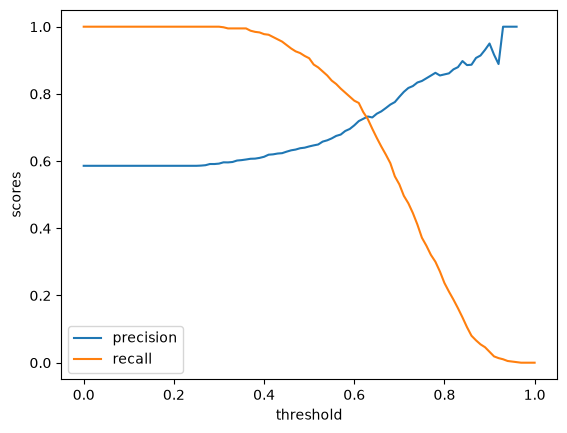

In [31]:
thresholds = np.linspace(0,1,101)
p, r, f1 = [], [], []
for t in thresholds:
    converted_decision = (y_pred >= t)

    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum() 

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    p.append(tp / (tp + fp))
    r.append(tp / (tp + fn))

    f1.append(2*p[-1]*r[-1]/(p[-1]+r[-1]))

plt.plot(thresholds, p, label = "precision")
plt.plot(thresholds, r, label = "recall")
plt.xlabel("threshold")
plt.ylabel("scores")
plt.legend()

print(thresholds[f1.index(max(f1))],max(f1))

In [39]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [40]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [47]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted .values
    y_val = df_val.converted .values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print('%.3f +- %.3f' % (np.mean(scores), np.std(scores)))

0.732 +- 0.007


In [50]:
n_splits = 5

for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06 0.732 +- 0.007
C=0.001 0.732 +- 0.007
C=1 0.732 +- 0.007
